# What actually controls tail latency in agentic LLM serving? (midterm findings)

**Started from:** *an oracle KV-replacement policy (Belady on known tool-return times) lowers p99 inter-turn TTFT.*
**Ended at:** the tail is an **admission-scheduling** problem. Replacement barely matters on this hardware.

| # | Finding | Evidence below |
|---|---|---|
| 1 | Oracle replacement doesn't improve latency. A PCIe reload costs ~0.1 s; tail turns wait minutes. | Part 1 |
| 2 | The tail is admission queueing: > 99 % of the slowest turns' TTFT is waiting to be admitted, and index-order admission starves late conversations. | Part 2 |
| 3 | Concurrency caps trade decode speed for queueing, and on average the queueing wins. Over 21 workloads, capped policies have 2–5 % worse mean E2E and worse tails than no cap; the 300K cap only looked good on the seed it was tuned on (42). | Part 3 |
| 4 | Fair admission (oldest waiting turn first) removes the tail. With no cap, p99 TTFT is 4–8× lower, p99 turn latency ~2.3× lower, and mean E2E equal or better. Our extra mechanisms add ~2 % on mean E2E on top of that. | Part 4 |
| 5 | Pushing TTFT lower by letting waiting turns bypass the cap only moves the wait. HBM overfills, running turns get preempted, and ~300 s of mid-generation waiting per conversation appears that TTFT does not see. | Part 5 |

**Setup.** `sim/` discrete-event simulator calibrated on H100 (decode cost model + measured PCIe bandwidth); Exgentic SWE-bench agent traces;
40 conversations per run, Poisson arrivals at λ = 0.15 conv/s, 48 GB and 64 GB of KV HBM. A **seed** fixes which 40 traces are drawn and when they
arrive; every policy sees the identical workload for a given seed.
Seeds **100–103** were used only to tune settings; results are on **21 held-out seeds** (1–20 and 42, the seed in `master_validation.ipynb`).
The hardware model was not changed for any policy.

**Metrics**
* **TTFT (inter-turn):** tool returns → first token of the next LLM call.
* **Turn latency:** turn ready (arrival / tool return) → that LLM call finishes. An agent can't run its next tool until the whole turn is done,
  so this is arguably the metric that matters most for agents. Unlike TTFT, it includes waits *after* a preemption.
* **Mean E2E:** conversation arrival → completion, averaged over conversations.

In [1]:
import os, json, gzip
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir(os.path.abspath(".."))
S = json.load(open("results/coop/summary.json"))
RAW = json.load(gzip.open("results/coop/ttft_rows.json.gz", "rt"))
SENS = json.load(open("results/coop/repl_sensitivity.json"))
SE21 = list(range(1, 21)) + [42]
SE6 = [1, 2, 3, 4, 5, 42]
DEV = [100, 101, 102, 103]

def runs(exp, lab, hbm, seeds=SE21):
    return [S[f"{exp}|{lab}|{hbm:.0f}|0.15|{s}"] for s in seeds]
def rows(exp, lab, hbm, seeds=SE21):
    return [np.array(RAW[f"{exp}|{lab}|{hbm:.0f}|0.15|{s}"]) for s in seeds]
cm = lambda k: (lambda s: s["coop_metrics"].get(k, 0.0))
p99 = lambda s: s["ttft_p99"]
p50 = lambda s: s["ttft_p50"]
e2e = lambda s: s["mean_e2e_s"]
dec = lambda s: s["state_seconds"]["DECODE"] / s["total_requests"]
mean = lambda xs, f: float(np.mean([f(x) for x in xs]))

ink, ink2, grid, bg = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({"font.size": 9, "axes.edgecolor": ink2, "axes.labelcolor": ink, "xtick.color": ink2,
                     "ytick.color": ink2, "axes.grid": True, "grid.color": grid, "grid.linewidth": 0.6,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.facecolor": bg,
                     "axes.facecolor": bg, "legend.frameon": False, "figure.dpi": 110})
# fixed colour per policy (never re-assigned between figures)
COL = {"Cap Oracle (300K)": "#eb6834", "Cap Oracle B_cap=12": "#1baf7a", "Uncapped Oracle": "#eda100",
       "turn-FIFO, no cap": "#8a63d2", "Coop (original)": "#e87ba4", "Coop + guard": "#2a78d6",
       "Coop sched + guard, LRU repl": "#7fb2ea"}
SHORT = {"Cap Oracle (300K)": "R_cap=300K", "Cap Oracle B_cap=12": "B_cap=12", "Uncapped Oracle": "Uncapped",
         "turn-FIFO, no cap": "turn-FIFO", "Coop (original)": "Coop (original)", "Coop + guard": "Coop + guard",
         "Coop sched + guard, LRU repl": "Coop + guard (LRU)"}
FIX = list(COL)
print("loaded", len(S), "runs")

loaded 970 runs


## Part 1: Oracle replacement does not improve latency

We compare the oracle (Paged Oracle: evict the KV whose tool returns furthest in the future, reload it just in time) with plain Paged LRU.

* **(a)** Under the original schedulers (6 seeds), with and without the 300K cap.
* **(b)** Under a fair scheduler, across tighter HBM and a PCIe link slowed to ½ and ¼ (6 seeds each). The PCIe slowdown is a sensitivity test,
  applied identically to every policy. Variants: Paged LRU, Paged Oracle, and our queue-aware oracle with prefetch.

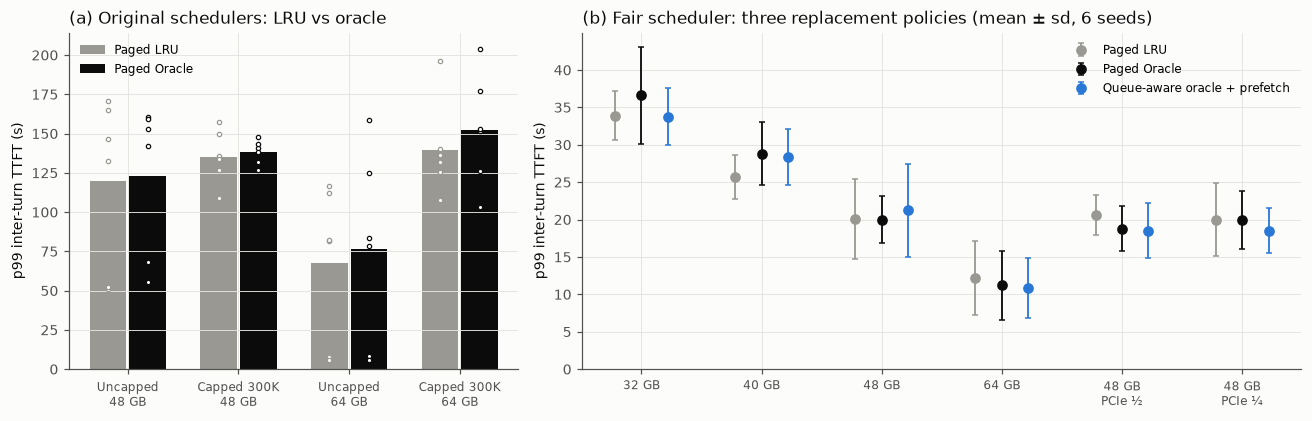

Mean reload stall per turn under the fair scheduler (s):
  32 GB         Paged LRU: 0.12  Paged Oracle: 0.33  Queue-aware oracle + prefetch: 0.30
  40 GB         Paged LRU: 0.12  Paged Oracle: 0.32  Queue-aware oracle + prefetch: 0.30
  48 GB PCIe ½  Paged LRU: 0.18  Paged Oracle: 0.34  Queue-aware oracle + prefetch: 0.30
  48 GB PCIe ¼  Paged LRU: 0.30  Paged Oracle: 0.47  Queue-aware oracle + prefetch: 0.43


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), gridspec_kw={"width_ratios": [1, 1.6]})
ax = axes[0]
pairs = [("Uncapped", "Uncapped LRU", "Uncapped Oracle"), ("Capped 300K", "Cap LRU (300K)", "Cap Oracle (300K)")]
x, w = 0, 0.36
ticks, labels = [], []
for hbm in (48.0, 64.0):
    for name, lru, orc in pairs:
        a = [p99(s) for s in runs("main", lru, hbm, SE6)]
        b = [p99(s) for s in runs("main", orc, hbm, SE6)]
        for off, v, c, lab in ((-w / 2, a, "#9a9893", "Paged LRU"), (w / 2, b, ink, "Paged Oracle")):
            ax.bar(x + off, np.mean(v), w * 0.92, color=c, label=lab if x == 0 else None)
            ax.scatter(np.full(len(v), x + off), v, s=8, color=bg, edgecolor=c, zorder=3, linewidth=0.8)
        ticks.append(x); labels.append(f"{name}\n{hbm:.0f} GB")
        x += 1
ax.set_xticks(ticks, labels, fontsize=8)
ax.set_ylabel("p99 inter-turn TTFT (s)")
ax.set_title("(a) Original schedulers: LRU vs oracle", loc="left", color=ink)
ax.legend(fontsize=8, loc="upper left")

ax = axes[1]
settings = [("32 GB", "sens", (32.0, 1.0)), ("40 GB", "sens", (40.0, 1.0)), ("48 GB", "abl", 48.0),
            ("64 GB", "abl", 64.0), ("48 GB\nPCIe ½", "sens", (48.0, 0.5)), ("48 GB\nPCIe ¼", "sens", (48.0, 0.25))]
variants = [("Paged LRU", "#9a9893", "fair sched + Paged LRU", "A6 coop sched + paged LRU repl"),
            ("Paged Oracle", ink, "fair sched + Paged Oracle", "A3 +soft cap = sched only"),
            ("Queue-aware oracle + prefetch", "#2a78d6", "fair sched + queue-aware Oracle + prefetch", "A5 full coop")]
for j, (nm, c, sens_lab, abl_lab) in enumerate(variants):
    xs, ms, sds = [], [], []
    for i, (_, kind, key) in enumerate(settings):
        if kind == "sens":
            v = [SENS[f"{key[0]:.0f}|{key[1]}|{sens_lab}|{sd}"]["p99"] for sd in SE6]
        else:
            v = [p99(s) for s in runs("ablation", abl_lab, key, SE6)]
        xs.append(i + (j - 1) * 0.22); ms.append(np.mean(v)); sds.append(np.std(v))
    ax.errorbar(xs, ms, yerr=sds, fmt="o", ms=6, color=c, ecolor=c, elinewidth=1.2, capsize=2, label=nm)
ax.set_xticks(range(len(settings)), [s[0] for s in settings], fontsize=8)
ax.set_ylim(0, None)
ax.set_ylabel("p99 inter-turn TTFT (s)")
ax.set_title("(b) Fair scheduler: three replacement policies (mean ± sd, 6 seeds)", loc="left", color=ink)
ax.legend(fontsize=8, loc="upper right")
fig.tight_layout(); plt.show()

print("Mean reload stall per turn under the fair scheduler (s):")
for (nm, kind, key) in settings:
    if kind != "sens":
        continue
    vals = {v[0]: np.mean([SENS[f"{key[0]:.0f}|{key[1]}|{v[2]}|{sd}"]["mean_stall"] for sd in SE6]) for v in variants}
    print(f"  {nm.replace(chr(10), ' '):14s}" + "  ".join(f"{k}: {x:.2f}" for k, x in vals.items()))

**Reading it.** In (a), LRU and oracle bars are equal within the seed spread: the oracle moves less data over PCIe but doesn't lower the tail.
In (b), the three policies overlap at every HBM size and even at ¼ PCIe bandwidth. The scheduler (compare with the ~140–190 s of the original
schedulers) matters far more. A reload costs ~0.1–0.5 s per turn, so even a perfect replacement policy has almost nothing to win.
The oracle variants even stall a little *more* than LRU: their just-in-time reload assumes a turn starts the moment its tool returns, and
under queueing it doesn't.

## Part 2: The tail is admission queueing

The slowest 1 % of turns, split into time spent **queueing** for admission, **PCIe reload stall**, and **prefill + batch step** (6 seeds pooled).

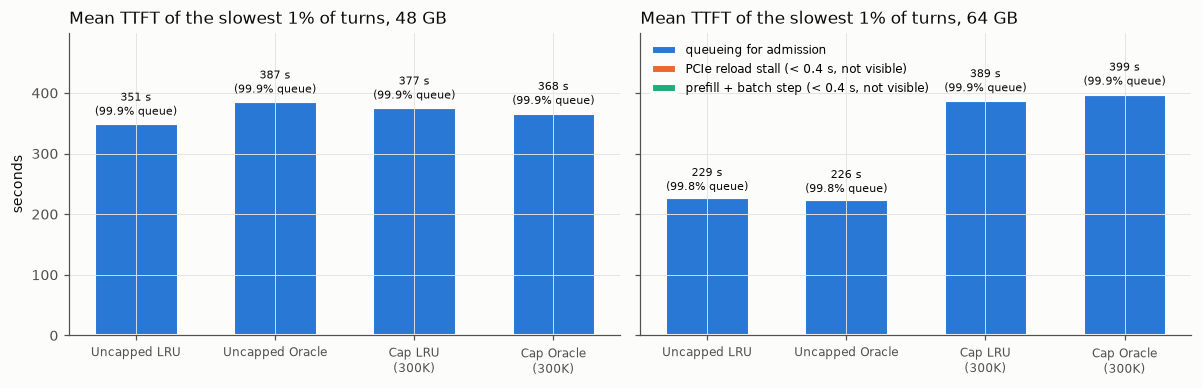

**Correlation between conversation index and its mean TTFT (48 GB, 6 seeds):** Uncapped LRU 0.75, Uncapped Oracle 0.72, Cap LRU (300K) 0.66, Cap Oracle (300K) 0.65. Admission walks conversations in index order and stops at the first that doesn't fit, so later conversations wait longest.

In [3]:
comp = [("queueing for admission", "#2a78d6"), ("PCIe reload stall (< 0.4 s, not visible)", "#eb6834"),
        ("prefill + batch step (< 0.4 s, not visible)", "#1baf7a")]
labs = ["Uncapped LRU", "Uncapped Oracle", "Cap LRU (300K)", "Cap Oracle (300K)"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, hbm in zip(axes, (48.0, 64.0)):
    vals = []
    for lab in labs:
        R = np.concatenate(rows("main", lab, hbm, SE6))
        X = R[R[:, 0] >= np.percentile(R[:, 0], 99)]
        vals.append((X[:, 1].mean(), X[:, 2].mean(), X[:, 3].mean()))
    vals = np.array(vals); bottom = np.zeros(len(labs))
    for j, (nm, c) in enumerate(comp):
        ax.bar(range(len(labs)), vals[:, j], 0.6, bottom=bottom, color=c, label=nm, edgecolor=bg, linewidth=2)
        bottom += vals[:, j]
    for i, t in enumerate(bottom):
        share = vals[i, 0] / t * 100
        ax.text(i, t * 1.02, f"{t:.0f} s\n({share:.1f}% queue)", ha="center", va="bottom", fontsize=7.5, color=ink)
    ax.set_xticks(range(len(labs)), [l.replace(" (", "\n(") for l in labs], fontsize=8)
    ax.set_ylim(0, bottom.max() * 1.25)
    ax.set_title(f"Mean TTFT of the slowest 1% of turns, {hbm:.0f} GB", loc="left", color=ink)
axes[0].set_ylabel("seconds"); axes[1].legend(fontsize=8, loc="upper left")
fig.tight_layout(); plt.show()

corr = {lab: np.mean([cm("conv_idx_ttft_corr")(s) for s in runs("main", lab, 48.0, SE6)]) for lab in labs}
display(Markdown("**Correlation between conversation index and its mean TTFT (48 GB, 6 seeds):** " +
                 ", ".join(f"{k} {v:.2f}" for k, v in corr.items()) +
                 ". Admission walks conversations in index order and stops at the first that doesn't fit, so later conversations wait longest."))

## Part 3: Concurrency caps trade decode speed for queueing, and on average lose

Each decode step costs more when more KV is active, so capping concurrency makes every conversation's **decode** faster. Turns then **wait** longer to get in.
Below: mean time per conversation by state (21 seeds, 48 GB), and the per-seed change in mean E2E vs no cap.

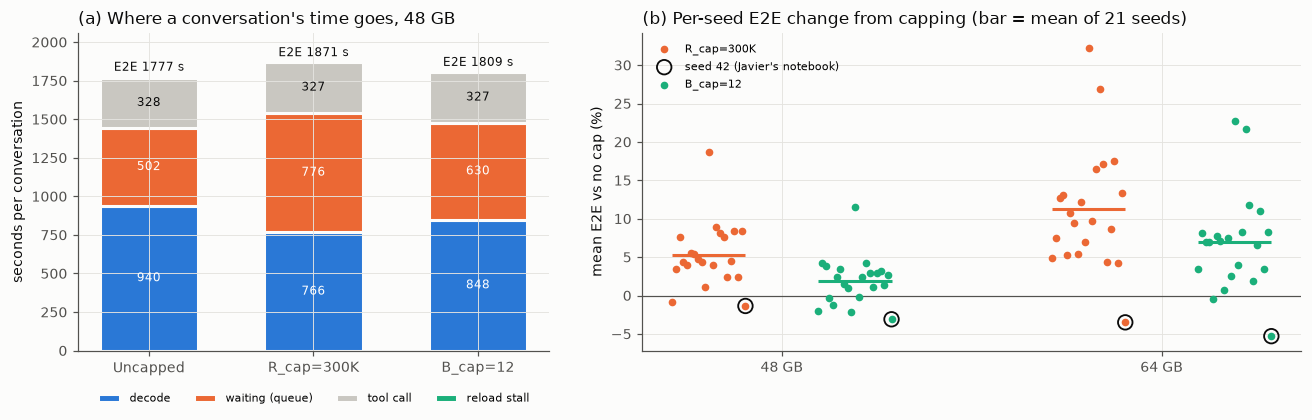

In [4]:
pols = ["Uncapped Oracle", "Cap Oracle (300K)", "Cap Oracle B_cap=12"]
states = [("DECODE", "decode", "#2a78d6"), ("WAITING", "waiting (queue)", "#eb6834"), ("TOOL", "tool call", "#c9c7c1"),
          ("STALL", "reload stall", "#1baf7a")]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), gridspec_kw={"width_ratios": [1, 1.4]})
ax = axes[0]
bottom = np.zeros(len(pols))
for key, nm, c in states:
    v = np.array([mean(runs("fix", p, 48.0), lambda s: s["state_seconds"].get(key, 0) / s["total_requests"]) for p in pols])
    ax.bar(range(len(pols)), v, 0.6, bottom=bottom, color=c, label=nm, edgecolor=bg, linewidth=2)
    for i in range(len(pols)):
        if v[i] > 120:
            ax.text(i, bottom[i] + v[i] / 2, f"{v[i]:.0f}", ha="center", va="center", fontsize=8, color=ink if key == "TOOL" else "white")
    bottom += v
for i, p in enumerate(pols):
    ax.text(i, bottom[i] * 1.01, f"E2E {mean(runs('fix', p, 48.0), e2e):.0f} s", ha="center", va="bottom", fontsize=8, color=ink)
ax.set_xticks(range(len(pols)), [SHORT[p] for p in pols])
ax.set_ylim(0, bottom.max() * 1.1)
ax.set_ylabel("seconds per conversation")
ax.set_title("(a) Where a conversation's time goes, 48 GB", loc="left", color=ink)
ax.legend(fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4)

ax = axes[1]
for k, hbm in enumerate((48.0, 64.0)):
    base = {s["seed"]: e2e(s) for s in runs("fix", "Uncapped Oracle", hbm)}
    for j, p in enumerate(pols[1:]):
        r = [(e2e(s) / base[s["seed"]] - 1) * 100 for s in runs("fix", p, hbm)]
        xpos = k * 2.6 + j + np.linspace(-0.25, 0.25, len(r))
        ax.scatter(xpos, r, s=16, color=COL[p], label=SHORT[p] if k == 0 else None, zorder=3)
        i42 = SE21.index(42)
        ax.scatter(xpos[i42], r[i42], s=90, facecolor="none", edgecolor=ink, linewidth=1.2, zorder=4,
                   label="seed 42 (Javier's notebook)" if (k == 0 and j == 0) else None)
        ax.hlines(np.mean(r), xpos[0], xpos[-1], color=COL[p], lw=2)
ax.axhline(0, color=ink2, lw=0.8)
ax.set_xticks([0.5, 3.1], ["48 GB", "64 GB"])
ax.set_ylabel("mean E2E vs no cap (%)")
ax.set_title("(b) Per-seed E2E change from capping (bar = mean of 21 seeds)", loc="left", color=ink)
ax.legend(fontsize=7.5, loc="upper left")
fig.tight_layout(); plt.show()

**Reading it.** In (a), the 300K cap cuts decode time per conversation but adds more than that in queueing, so mean E2E rises.
In (b), each dot is one workload. Capping makes mean E2E worse on most seeds. **Seed 42 (circled) is one of the few where it helps**, which is
why the single-seed result in `master_validation.ipynb` pointed the other way (and the 300K value was itself chosen on seed 42).

## Part 4: Fair admission removes the tail

**turn-FIFO** admits the turn that has waited longest, with no cap: essentially vLLM-style FCFS at the turn level.
**Coop + guard** is our scheduler: oldest-first once a turn has waited ≥ 1 s, a soft 300K cap, backfill, and a headroom guard that
stops it overfilling HBM. Its settings were chosen on dev seeds 100–103 (table at the end).

In [5]:
main_pols = ["Cap Oracle (300K)", "Cap Oracle B_cap=12", "Uncapped Oracle", "turn-FIFO, no cap", "Coop + guard"]
def fmt_table(hbm):
    head = "| policy | p99 TTFT | p50 TTFT | p99 turn latency | mean E2E | decode / conv | PCIe H2D |\n|---|---|---|---|---|---|---|\n"
    out = ""
    for p in FIX:
        R = runs("fix", p, hbm)
        out += (f"| {SHORT[p]} | {mean(R, p99):.1f} s | {mean(R, p50):.2f} s | {mean(R, cm('turn_lat_p99')):.0f} s | "
                f"{mean(R, e2e):.0f} s | {mean(R, dec):.0f} s | {mean(R, cm('pcie_h2d_gb')):.0f} GB |\n")
    return head + out
for hbm in (48.0, 64.0):
    display(Markdown(f"**{hbm:.0f} GB, mean of 21 held-out seeds**\n\n" + fmt_table(hbm)))

**48 GB, mean of 21 held-out seeds**

| policy | p99 TTFT | p50 TTFT | p99 turn latency | mean E2E | decode / conv | PCIe H2D |
|---|---|---|---|---|---|---|
| R_cap=300K | 187.0 s | 1.33 s | 394 s | 1871 s | 766 s | 1717 GB |
| B_cap=12 | 99.4 s | 0.97 s | 355 s | 1809 s | 848 s | 2241 GB |
| Uncapped | 142.1 s | 0.96 s | 282 s | 1777 s | 940 s | 3258 GB |
| turn-FIFO | 38.4 s | 10.18 s | 167 s | 1780 s | 964 s | 4524 GB |
| Coop (original) | 23.3 s | 2.90 s | 298 s | 1789 s | 963 s | 3942 GB |
| Coop + guard | 42.8 s | 8.16 s | 166 s | 1752 s | 965 s | 4466 GB |
| Coop + guard (LRU) | 43.4 s | 8.05 s | 166 s | 1752 s | 965 s | 4448 GB |


**64 GB, mean of 21 held-out seeds**

| policy | p99 TTFT | p50 TTFT | p99 turn latency | mean E2E | decode / conv | PCIe H2D |
|---|---|---|---|---|---|---|
| R_cap=300K | 179.9 s | 1.29 s | 374 s | 1868 s | 767 s | 433 GB |
| B_cap=12 | 85.0 s | 0.86 s | 357 s | 1795 s | 867 s | 508 GB |
| Uncapped | 70.6 s | 0.58 s | 209 s | 1684 s | 1142 s | 2585 GB |
| turn-FIFO | 22.7 s | 2.70 s | 182 s | 1681 s | 1151 s | 3190 GB |
| Coop (original) | 13.0 s | 1.46 s | 220 s | 1687 s | 1102 s | 2169 GB |
| Coop + guard | 24.2 s | 2.35 s | 181 s | 1669 s | 1138 s | 3138 GB |
| Coop + guard (LRU) | 24.5 s | 2.49 s | 180 s | 1672 s | 1139 s | 3302 GB |


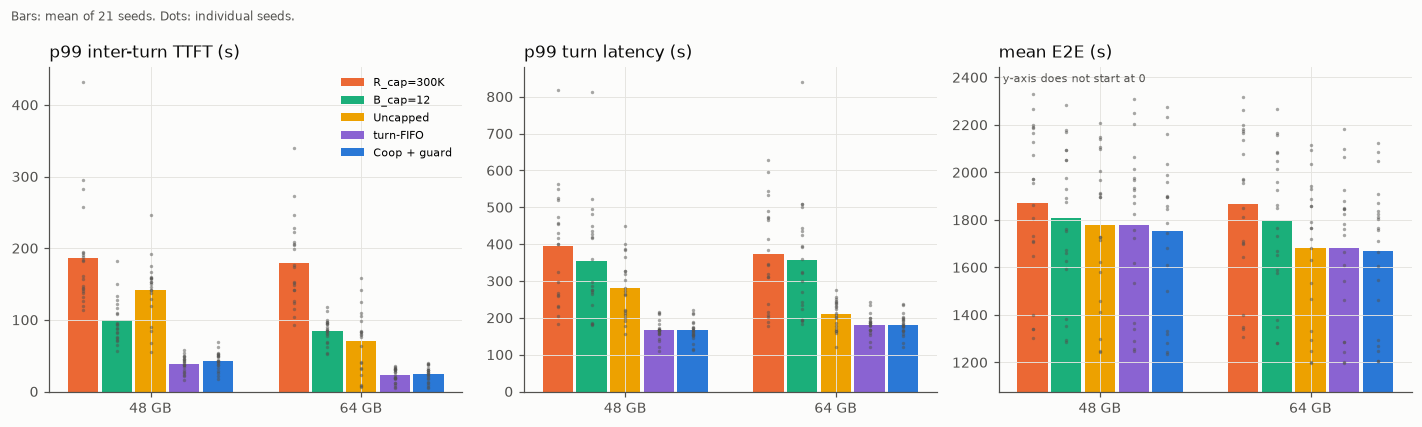

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
mets = [(p99, "p99 inter-turn TTFT (s)"), (cm("turn_lat_p99"), "p99 turn latency (s)"), (e2e, "mean E2E (s)")]
w = 0.16
for ax, (f, title) in zip(axes, mets):
    for j, p in enumerate(main_pols):
        for k, hbm in enumerate((48.0, 64.0)):
            v = [f(s) for s in runs("fix", p, hbm)]
            xc = k + (j - 2) * w
            ax.bar(xc, np.mean(v), w * 0.9, color=COL[p], label=SHORT[p] if k == 0 else None)
            ax.scatter(np.full(len(v), xc), v, s=5, color=ink2, alpha=0.5, zorder=3, linewidth=0)
    ax.set_xticks([0, 1], ["48 GB", "64 GB"])
    ax.set_title(title, loc="left", color=ink)
    if f is e2e:
        lo = min(min(e2e(s) for s in runs("fix", p, h)) for p in main_pols for h in (48.0, 64.0))
        ax.set_ylim(lo * 0.9, None)
        ax.text(0.01, 0.98, "y-axis does not start at 0", transform=ax.transAxes, fontsize=7, color=ink2, va="top")
axes[0].legend(fontsize=7.5, loc="upper right")
fig.suptitle("Bars: mean of 21 seeds. Dots: individual seeds.", x=0.01, ha="left", fontsize=8, color=ink2)
fig.tight_layout(); plt.show()

In [7]:
def paired(a, b, f, hbm):
    A = {s["seed"]: f(s) for s in runs("fix", a, hbm)}; B = {s["seed"]: f(s) for s in runs("fix", b, hbm)}
    r = np.array([A[k] / B[k] for k in SE21])
    return f"{np.exp(np.log(r).mean()):.2f}× ({(r < 1).sum()}/21)"
txt = "**Paired per-seed comparison:** geometric-mean ratio *a / b* (number of seeds where *a* is lower)\n\n"
txt += "| a vs b | HBM | p99 TTFT | p99 turn latency | mean E2E |\n|---|---|---|---|---|\n"
for a, b in [("turn-FIFO, no cap", "Cap Oracle (300K)"), ("turn-FIFO, no cap", "Cap Oracle B_cap=12"),
             ("Coop + guard", "Cap Oracle (300K)"), ("Coop + guard", "Cap Oracle B_cap=12"),
             ("Coop + guard", "turn-FIFO, no cap"), ("Coop sched + guard, LRU repl", "Coop + guard")]:
    for hbm in (48.0, 64.0):
        txt += (f"| {SHORT[a]} vs {SHORT[b]} | {hbm:.0f} GB | {paired(a, b, p99, hbm)} | "
                f"{paired(a, b, cm('turn_lat_p99'), hbm)} | {paired(a, b, e2e, hbm)} |\n")
display(Markdown(txt))

**Paired per-seed comparison:** geometric-mean ratio *a / b* (number of seeds where *a* is lower)

| a vs b | HBM | p99 TTFT | p99 turn latency | mean E2E |
|---|---|---|---|---|
| turn-FIFO vs R_cap=300K | 48 GB | 0.21× (21/21) | 0.45× (21/21) | 0.95× (16/21) |
| turn-FIFO vs R_cap=300K | 64 GB | 0.12× (21/21) | 0.52× (21/21) | 0.90× (20/21) |
| turn-FIFO vs B_cap=12 | 48 GB | 0.38× (21/21) | 0.50× (21/21) | 0.98× (14/21) |
| turn-FIFO vs B_cap=12 | 64 GB | 0.24× (21/21) | 0.55× (21/21) | 0.93× (17/21) |
| Coop + guard vs R_cap=300K | 48 GB | 0.23× (21/21) | 0.45× (21/21) | 0.93× (17/21) |
| Coop + guard vs R_cap=300K | 64 GB | 0.12× (21/21) | 0.51× (21/21) | 0.89× (20/21) |
| Coop + guard vs B_cap=12 | 48 GB | 0.43× (21/21) | 0.50× (21/21) | 0.97× (16/21) |
| Coop + guard vs B_cap=12 | 64 GB | 0.26× (21/21) | 0.54× (21/21) | 0.93× (18/21) |
| Coop + guard vs turn-FIFO | 48 GB | 1.11× (1/21) | 0.99× (12/21) | 0.98× (21/21) |
| Coop + guard vs turn-FIFO | 64 GB | 1.06× (7/21) | 0.99× (14/21) | 0.99× (15/21) |
| Coop + guard (LRU) vs Coop + guard | 48 GB | 1.01× (8/21) | 1.00× (9/21) | 1.00× (11/21) |
| Coop + guard (LRU) vs Coop + guard | 64 GB | 1.02× (9/21) | 1.00× (13/21) | 1.00× (8/21) |


**Reading it.**
* Plain **turn-FIFO** already beats both capped baselines on p99 TTFT and p99 turn latency on (almost) every seed, with equal or better mean E2E.
  That is the core result: **the fix for the tail is fair ordering, not a cap and not replacement.**
* **Coop + guard** is nearly the same as turn-FIFO. Mean E2E is ~2 % better on (nearly) every seed and p50 is a little better at 48 GB,
  but p99 TTFT is ~10 % worse. Our extra machinery is a small refinement, not the source of the gain.
* Swapping the oracle for LRU inside Coop + guard changes nothing (last row), consistent with Part 1.
* Honest caveat: part of the improvement over the R_cap / B_cap baselines is that their index-order admission is unusually unfair. Real vLLM
  uses an FCFS waiting queue, which behaves more like turn-FIFO.

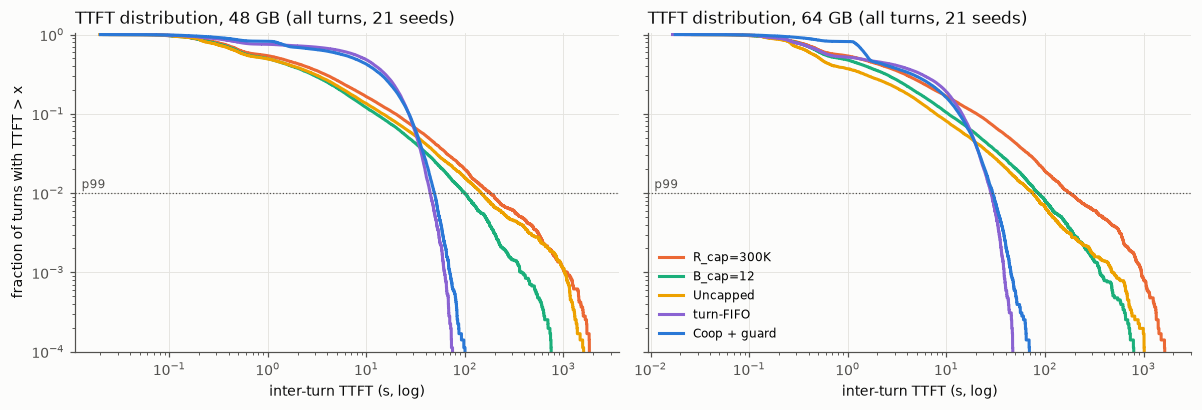

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, hbm in zip(axes, (48.0, 64.0)):
    for p in main_pols:
        x = np.sort(np.concatenate([r[:, 0] for r in rows("fix", p, hbm)]))
        y = 1 - np.arange(1, len(x) + 1) / len(x)
        ax.step(x, np.maximum(y, 1e-5), where="post", color=COL[p], lw=2, label=SHORT[p])
    ax.axhline(0.01, color=ink2, lw=0.8, ls=":")
    ax.text(0.012, 0.0115, "p99", color=ink2, fontsize=8, transform=ax.get_yaxis_transform())
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(1e-4, 1.05)
    ax.set_xlabel("inter-turn TTFT (s, log)")
    ax.set_title(f"TTFT distribution, {hbm:.0f} GB (all turns, 21 seeds)", loc="left", color=ink)
axes[0].set_ylabel("fraction of turns with TTFT > x"); axes[1].legend(fontsize=8, loc="lower left")
fig.tight_layout(); plt.show()

The fair policies cost a little at the median: turns that would have been admitted instantly now sometimes wait behind older ones.
In exchange, the tail beyond ~10 s mostly disappears.

## Part 5: Lower TTFT by bypassing the cap only moves the wait

**Coop (original)** lets a turn that has waited ≥ 1 s exceed the cap *without* the headroom guard. HBM then fills with active KV. When a running
request needs one more block, the engine **preempts** the most recently admitted request, which goes back to the queue and later recomputes
its KV. That request has already produced its first token, so the time it spends re-queued **never shows up in TTFT**; it shows up in turn
latency and E2E.

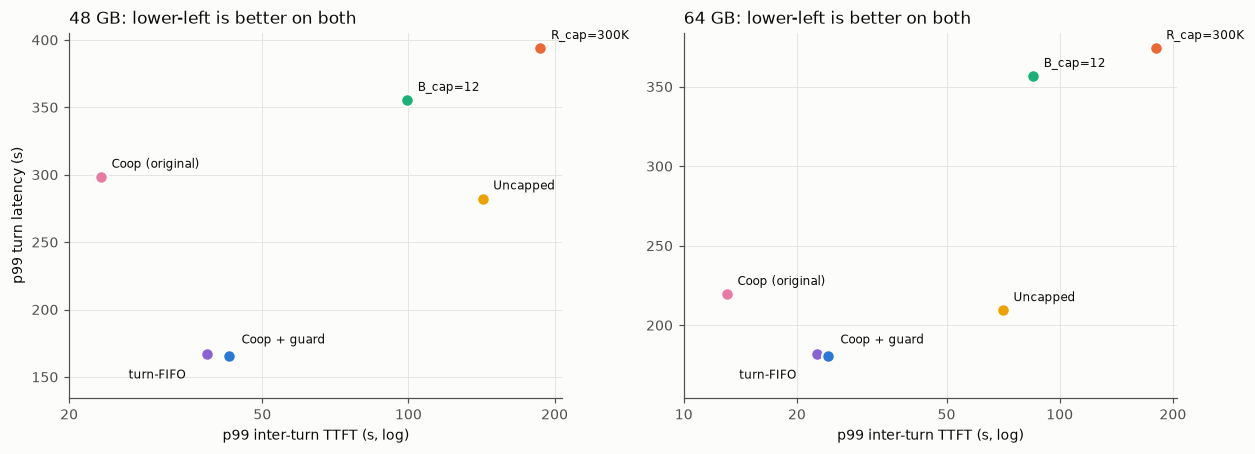

| policy | HBM | preemptions / run | post-preemption wait / conv | share of turns preempted |
|---|---|---|---|---|
| Uncapped | 48 GB | 10.6 | 2 s | 0.6 % |
| Uncapped | 64 GB | 6.5 | 2 s | 0.4 % |
| turn-FIFO | 48 GB | 9.7 | 0 s | 0.6 % |
| turn-FIFO | 64 GB | 5.7 | 0 s | 0.3 % |
| Coop (original) | 48 GB | 16.2 | 297 s | 0.9 % |
| Coop (original) | 64 GB | 6.3 | 160 s | 0.4 % |
| Coop + guard | 48 GB | 0.0 | 0 s | 0.0 % |
| Coop + guard | 64 GB | 0.0 | 3 s | 0.0 % |


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), sharey=False)
for ax, hbm in zip(axes, (48.0, 64.0)):
    for p in FIX[:-1]:                                  # LRU variant sits exactly on Coop + guard
        R = runs("fix", p, hbm)
        x, y = mean(R, p99), mean(R, cm("turn_lat_p99"))
        ax.scatter(x, y, s=70, color=COL[p], edgecolor=bg, linewidth=1.5, zorder=3)
        off = {"turn-FIFO, no cap": (-14, -16, "right"), "Coop + guard": (8, 8, "left")}.get(p, (7, 6, "left"))
        ax.annotate(SHORT[p], (x, y), xytext=off[:2], textcoords="offset points", fontsize=8, color=ink, ha=off[2])
    ax.set_xscale("log")
    tk = [t for t in (10, 20, 50, 100, 200) if 0.7 * ax.get_xlim()[0] <= t <= 1.3 * ax.get_xlim()[1]]
    ax.set_xticks(tk, [str(t) for t in tk]); ax.minorticks_off()
    lo, hi = ax.get_ylim(); ax.set_ylim(lo - 0.08 * (hi - lo), hi)
    ax.set_xlabel("p99 inter-turn TTFT (s, log)")
    ax.set_title(f"{hbm:.0f} GB: lower-left is better on both", loc="left", color=ink)
axes[0].set_ylabel("p99 turn latency (s)")
fig.tight_layout(); plt.show()

txt = "| policy | HBM | preemptions / run | post-preemption wait / conv | share of turns preempted |\n|---|---|---|---|---|\n"
for p in ["Uncapped Oracle", "turn-FIFO, no cap", "Coop (original)", "Coop + guard"]:
    for hbm in (48.0, 64.0):
        R = runs("fix", p, hbm)
        txt += (f"| {SHORT[p]} | {hbm:.0f} GB | {mean(R, cm('preemptions')):.1f} | {mean(R, cm('preempt_wait_per_conv')):.0f} s | "
                f"{mean(R, cm('turns_preempted_frac')) * 100:.1f} % |\n")
display(Markdown(txt))

**Reading it.** Coop (original) has the lowest p99 TTFT, but on the turn-latency axis it is worse than turn-FIFO and Coop + guard
(1.7× worse p99 turn latency than turn-FIFO at 48 GB, on all 21 seeds). The ~300 s per conversation of post-preemption waiting is what TTFT
misses. With the headroom guard there are no preemptions, and Coop lands next to turn-FIFO.

### Seed 42 in detail (the seed in Javier's plots)

Mean seconds per conversation at 48 GB. *Inter-turn queue* is what TTFT measures; *post-preemption wait* is invisible to it.

In [10]:
txt = "| policy | first-turn wait | inter-turn queue | post-preemption wait | decode | mean E2E | p99 TTFT | p99 turn latency |\n|---|---|---|---|---|---|---|---|\n"
for p in ["Cap Oracle (300K)", "Cap Oracle B_cap=12", "Uncapped Oracle", "turn-FIFO, no cap", "Coop (original)", "Coop + guard"]:
    k = f"fix|{p}|48|0.15|42"
    s, R = S[k], np.array(RAW[k]); n = s["total_requests"]; c = s["coop_metrics"]
    txt += (f"| {SHORT[p]} | {c['first_turn_wait_mean']:.0f} | {R[:, 1].sum() / n:.0f} | {c['preempt_wait_per_conv']:.0f} | "
            f"{dec(s):.0f} | {e2e(s):.0f} | {p99(s):.0f} | {c['turn_lat_p99']:.0f} |\n")
display(Markdown(txt))

| policy | first-turn wait | inter-turn queue | post-preemption wait | decode | mean E2E | p99 TTFT | p99 turn latency |
|---|---|---|---|---|---|---|---|
| R_cap=300K | 149 | 465 | 0 | 744 | 1705 | 143 | 259 |
| B_cap=12 | 314 | 215 | 0 | 798 | 1675 | 74 | 184 |
| Uncapped | 7 | 458 | 1 | 909 | 1729 | 159 | 214 |
| turn-FIFO | 1 | 632 | 0 | 940 | 1927 | 48 | 161 |
| Coop (original) | 1 | 232 | 390 | 947 | 1930 | 31 | 218 |
| Coop + guard | 1 | 604 | 0 | 938 | 1897 | 53 | 158 |


On seed 42 the capped, index-ordered policies have the best mean E2E. They finish the early conversations quickly and make late ones wait
before their first turn, which favours the average but produces the bad tail. Every fair policy pays ~10–13 % in mean E2E on this seed;
across all 21 seeds that reverses (Part 3b, Part 4).

## Appendix: how Coop + guard's settings were chosen (dev seeds 100–103 only)

`D` = seconds a turn must wait before it is urgent; `pf` = preempted turns go to the queue head; `guard` = urgent turns may exceed the cap only while
non-evictable KV + the turn + expected decode growth stays ≤ guard × HBM. The rule fixed in advance: low p99 TTFT, but no preemption-driven
turn-latency blow-up and mean E2E no worse than the baselines. Guard = 1.0 with D = 1 was best among the guarded variants at both HBM sizes.
With the guard on, `pf` has no effect, because nothing is preempted.

In [11]:
labs = []
for k in S:
    e, l = k.split("|")[:2]
    if e == "fixdev" and l not in labs:
        labs.append(l)
txt = "| config | HBM | p99 TTFT | p50 TTFT | p99 turn latency | mean E2E | preemptions |\n|---|---|---|---|---|---|---|\n"
for l in labs:
    if "pf=1" in l and "guard=None" not in l:
        continue                                        # identical to pf=0 once the guard is on
    for hbm in (48.0, 64.0):
        R = runs("fixdev", l, hbm, DEV)
        txt += (f"| {l} | {hbm:.0f} | {mean(R, p99):.1f} | {mean(R, p50):.2f} | {mean(R, cm('turn_lat_p99')):.0f} | "
                f"{mean(R, e2e):.0f} | {mean(R, cm('preemptions')):.1f} |\n")
display(Markdown(txt))

| config | HBM | p99 TTFT | p50 TTFT | p99 turn latency | mean E2E | preemptions |
|---|---|---|---|---|---|---|
| Cap Oracle (300K) | 48 | 215.3 | 1.11 | 378 | 1838 | 0.0 |
| Cap Oracle (300K) | 64 | 189.2 | 1.14 | 347 | 1845 | 0.0 |
| Uncapped Oracle | 48 | 152.7 | 0.95 | 258 | 1709 | 8.8 |
| Uncapped Oracle | 64 | 56.9 | 0.53 | 190 | 1575 | 6.0 |
| Cap Oracle B_cap=12 | 48 | 85.8 | 0.93 | 296 | 1757 | 2.0 |
| Cap Oracle B_cap=12 | 64 | 101.0 | 0.79 | 320 | 1741 | 0.0 |
| D=0 pf=0 guard=None | 48 | 21.8 | 2.29 | 245 | 1654 | 11.5 |
| D=0 pf=0 guard=None | 64 | 12.0 | 0.46 | 212 | 1599 | 6.0 |
| D=0 pf=0 guard=0.85 | 48 | 47.9 | 11.46 | 138 | 1709 | 0.0 |
| D=0 pf=0 guard=0.85 | 64 | 31.4 | 4.58 | 156 | 1611 | 0.0 |
| D=0 pf=0 guard=0.9 | 48 | 46.1 | 9.84 | 136 | 1689 | 0.0 |
| D=0 pf=0 guard=0.9 | 64 | 29.3 | 3.47 | 160 | 1592 | 0.0 |
| D=0 pf=0 guard=0.95 | 48 | 45.0 | 8.54 | 141 | 1664 | 0.0 |
| D=0 pf=0 guard=0.95 | 64 | 26.6 | 2.23 | 166 | 1577 | 0.0 |
| D=0 pf=0 guard=1.0 | 48 | 42.4 | 7.09 | 143 | 1645 | 0.0 |
| D=0 pf=0 guard=1.0 | 64 | 23.2 | 1.26 | 169 | 1561 | 0.0 |
| D=0 pf=1 guard=None | 48 | 41.3 | 7.54 | 146 | 1678 | 26.8 |
| D=0 pf=1 guard=None | 64 | 23.0 | 1.42 | 172 | 1579 | 13.5 |
| D=1 pf=0 guard=None | 48 | 22.7 | 3.11 | 234 | 1686 | 14.0 |
| D=1 pf=0 guard=None | 64 | 11.9 | 1.43 | 216 | 1591 | 7.0 |
| D=1 pf=0 guard=0.85 | 48 | 48.2 | 11.74 | 135 | 1716 | 0.0 |
| D=1 pf=0 guard=0.85 | 64 | 32.1 | 4.89 | 154 | 1615 | 0.0 |
| D=1 pf=0 guard=0.9 | 48 | 45.0 | 10.14 | 137 | 1689 | 0.0 |
| D=1 pf=0 guard=0.9 | 64 | 28.2 | 3.71 | 158 | 1596 | 0.0 |
| D=1 pf=0 guard=0.95 | 48 | 42.9 | 8.87 | 139 | 1669 | 0.0 |
| D=1 pf=0 guard=0.95 | 64 | 26.5 | 2.82 | 163 | 1583 | 0.0 |
| D=1 pf=0 guard=1.0 | 48 | 40.2 | 7.13 | 142 | 1648 | 0.0 |
| D=1 pf=0 guard=1.0 | 64 | 21.6 | 2.15 | 167 | 1567 | 0.0 |
| D=1 pf=1 guard=None | 48 | 40.5 | 7.52 | 152 | 1682 | 27.0 |
| D=1 pf=1 guard=None | 64 | 21.0 | 2.33 | 170 | 1585 | 13.8 |


## Caveats and next steps

* **Simulator only**, one trace family (SWE-bench agents), 40 conversations per run, one arrival rate (λ = 0.15). Next: higher load, a second trace,
  and checking real vLLM's FCFS behaviour against turn-FIFO.
* The original baseline admission (index order, stop at the first request that doesn't fit) is unusually unfair, which inflates the gap between it and any
  fair policy. turn-FIFO is the baseline to beat.
* Replacement could still matter where a reload is expensive: slow or shared PCIe, much longer contexts, limited CPU memory, or recompute-only setups.
  We haven't tested those.
* TTFT alone can be gamed by preempting running work. **Report p99 turn latency alongside TTFT.**

**Code:** `sim/coop_sim.py` (policies + measurement; baselines in `sim/paged_vs_oracle.py` unchanged), `sim/run_coop_experiments.py`
(`fixdev`, `fix` experiments), `sim/run_repl_sensitivity.py` (Part 1b), this notebook's builder `sim/tools/build_fair_notebook.py`.